# 0. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data

In [2]:
df = pd.read_csv('/content/boston.csv')
df

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


#  2. Data Understanding

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [4]:
df.duplicated().sum()

np.int64(0)

# 3. Checking Multicolinearity

In [5]:
from sklearn.model_selection import train_test_split

feature = df.drop(columns='medv')
target = df[['medv']]

feature_medv_train, feature_medv_test, target_medv_train, target_medv_test = train_test_split(feature, target, test_size=0.20, random_state=42)

## 3.1 Checking Multicolinearity by VIF Score

In [6]:
# calculate VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

X = add_constant(feature_medv_train)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df

,feature,vif_score
1,crim,1.713187
2,zn,2.465631
3,indus,3.877855
4,chas,1.096674
5,nox,4.469150
6,rm,1.947809
7,age,2.989948
8,dis,4.168578
9,rad,7.658316
10,tax,8.943301


## 3.2 Checking Multicolinearity by Correalation Heatmap

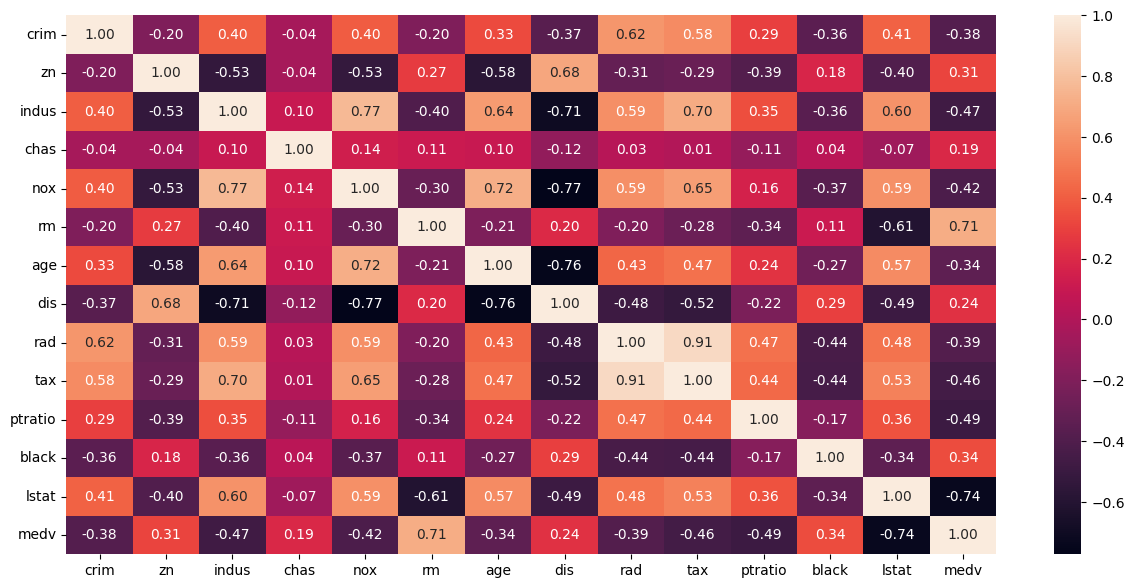

In [7]:
medv_train = pd.concat([feature_medv_train, target_medv_train], axis=1)
corr = medv_train.corr()

plt.figure(figsize=(15,7))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

In [8]:
feature_medv_train = feature_medv_train.drop(columns=['rad'])
feature_medv_test = feature_medv_test.drop(columns=['rad'])

Melakukan drop kolom rad karena memiliki vif score yang tinggi dan dilihat dari korelasi kolom rad memiliki korelasi yang tinggi (>0.8) dengan kolom tax. Kolom tax dipertahankan karena memiliki korelasi yang tinggi terhadap medv dibandingkan kolom rad.
Tidak melakukan drop pada kolom nox ataupun dis karena nilai korelasi masih dibawah 0.8 walaupun nilai VIF sudah menyentuh angka 4

In [9]:
X = add_constant(feature_medv_train)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df

,feature,vif_score
1,crim,1.593872
2,zn,2.413664
3,indus,3.658237
4,chas,1.084671
5,nox,4.411973
6,rm,1.884987
7,age,2.977080
8,dis,4.166015
9,tax,3.331299
10,ptratio,1.776290


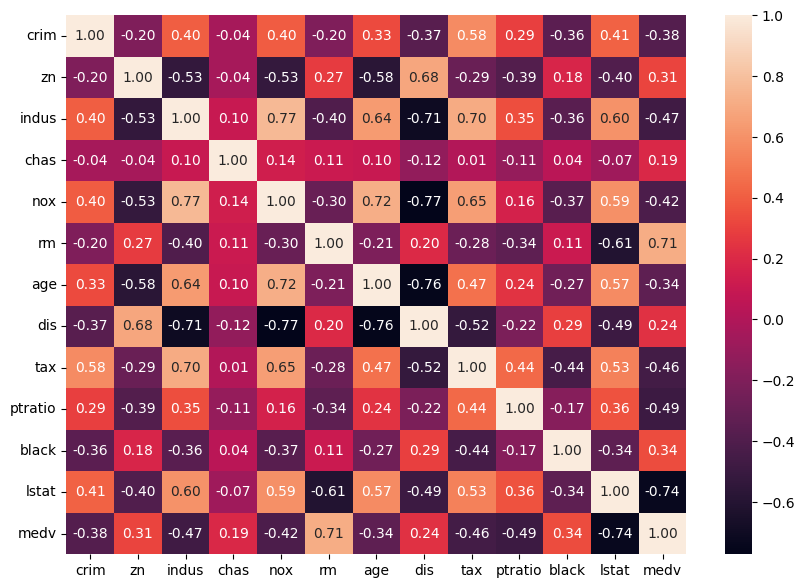

In [10]:
medv_train = pd.concat([feature_medv_train, target_medv_train], axis=1)
corr = medv_train.corr()

plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

# 5. Machine Learning Proses

## 5.1 Splitting Data

In [11]:
# split train test
from sklearn.model_selection import train_test_split

feature = df.drop(columns='medv')
target = df[['medv']]

# First splitting: pretrain and test
feature_medv_pretrain, feature_medv_test, target_medv_pretrain, target_medv_test = train_test_split(feature, target, test_size=0.20, random_state=42)

# Second splitting: train and validation
feature_medv_train, feature_medv_validation, target_medv_train, target_medv_validation = train_test_split(feature_medv_pretrain, target_medv_pretrain, test_size=0.20, random_state=42)

In [12]:
feature_medv_test = feature_medv_test.drop(columns=['rad'])
feature_medv_train = feature_medv_train.drop(columns=['rad'])
feature_medv_validation = feature_medv_validation.drop(columns=['rad'])

## 5.2 Machine Learning Ridge

In [13]:
from sklearn.linear_model import Ridge

X_medv_train = feature_medv_train.to_numpy()
y_medv_train = target_medv_train.to_numpy()
y_medv_train = y_medv_train.reshape(len(y_medv_train),)


ridge_reg_1 = Ridge(alpha=0.0001, random_state=42)
ridge_reg_2 = Ridge(alpha=0.001, random_state=42)
ridge_reg_3 = Ridge(alpha=0.01, random_state=42)
ridge_reg_4 = Ridge(alpha=0.1, random_state=42)
ridge_reg_5 = Ridge(alpha=1, random_state=42)
ridge_reg_6 = Ridge(alpha=10, random_state=42)
ridge_reg_7 = Ridge(alpha=100, random_state=42)
ridge_reg_8 = Ridge(alpha=1000, random_state=42)

# fit the model (training)
ridge_reg_1.fit(X_medv_train, y_medv_train)
ridge_reg_2.fit(X_medv_train, y_medv_train)
ridge_reg_3.fit(X_medv_train, y_medv_train)
ridge_reg_4.fit(X_medv_train, y_medv_train)
ridge_reg_5.fit(X_medv_train, y_medv_train)
ridge_reg_6.fit(X_medv_train, y_medv_train)
ridge_reg_7.fit(X_medv_train, y_medv_train)
ridge_reg_8.fit(X_medv_train, y_medv_train)

Ridge(alpha=1000, random_state=42)

In [14]:
from sklearn.metrics import mean_squared_error

X_medv_validation = feature_medv_validation.to_numpy()
y_medv_validation = target_medv_validation.to_numpy()
y_medv_validation = y_medv_validation.reshape(len(y_medv_validation),)

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
models = [ridge_reg_1,
          ridge_reg_2,
          ridge_reg_3,
          ridge_reg_4,
          ridge_reg_5,
          ridge_reg_6,
          ridge_reg_7,
          ridge_reg_8]

for model, alpha in zip(models, alphas):
    y_predict_validation = model.predict(X_medv_validation)
    rmse = np.sqrt(mean_squared_error(y_medv_validation,y_predict_validation))
    print(f'RMSE of Ridge regression model with alpha = {alpha} is {rmse}')

RMSE of Ridge regression model with alpha = 0.0001 is 4.962134042990084
RMSE of Ridge regression model with alpha = 0.001 is 4.961999535301614
RMSE of Ridge regression model with alpha = 0.01 is 4.960676932957843
RMSE of Ridge regression model with alpha = 0.1 is 4.94941253512279
RMSE of Ridge regression model with alpha = 1 is 4.912351371579992
RMSE of Ridge regression model with alpha = 10 is 4.871717983886228
RMSE of Ridge regression model with alpha = 100 is 4.791025827798375
RMSE of Ridge regression model with alpha = 1000 is 4.978139061616782


Berdasarkan hasil RMSE diketahui bahwa best model untuk machine learning ridge adalah menggunakan alpha 100 dengan hasil RMSE terendah yaitu 4.791

In [15]:
ridge_best = ridge_reg_7

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_medv_train.columns.tolist(),
    'coefficient':[ridge_best.intercept_] + list(ridge_best.coef_)
})

coef_df

,feature,coefficient
0,intercept,29.935814
1,crim,-0.068737
2,zn,0.036665
3,indus,-0.099467
4,chas,0.545787
5,nox,-0.152648
6,rm,2.611269
7,age,0.011538
8,dis,-1.131531
9,tax,-0.001263


## 5.3 Machine Learning Lasso

In [16]:
from sklearn.linear_model import Lasso

# train the model
X_medv_validation = feature_medv_validation.to_numpy()
y_medv_train = target_medv_train.to_numpy()
y_medv_train = y_medv_train.reshape(len(y_medv_train),)

# define the model
# 4 models with 4 different alphas (lambda)
Lasso_reg_1 = Lasso(alpha=0.00001, random_state=42)
Lasso_reg_2 = Lasso(alpha=0.0001, random_state=42)
Lasso_reg_3 = Lasso(alpha=0.001, random_state=42)
Lasso_reg_4 = Lasso(alpha=0.01, random_state=42)
Lasso_reg_5 = Lasso(alpha=0.1, random_state=42)
Lasso_reg_6 = Lasso(alpha=1, random_state=42)
Lasso_reg_7 = Lasso(alpha=10, random_state=42)

# fit the model (training)
Lasso_reg_1.fit(X_medv_train, y_medv_train)
Lasso_reg_2.fit(X_medv_train, y_medv_train)
Lasso_reg_3.fit(X_medv_train, y_medv_train)
Lasso_reg_4.fit(X_medv_train, y_medv_train)
Lasso_reg_5.fit(X_medv_train, y_medv_train)
Lasso_reg_6.fit(X_medv_train, y_medv_train)
Lasso_reg_7.fit(X_medv_train, y_medv_train)

Lasso(alpha=10, random_state=42)

In [17]:
from sklearn.metrics import mean_squared_error

y_medv_validation = target_medv_validation.to_numpy()
y_medv_validation = y_medv_validation.reshape(len(y_medv_validation),)

alphas = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]
models = [Lasso_reg_1,
          Lasso_reg_2,
          Lasso_reg_3,
          Lasso_reg_4,
          Lasso_reg_5,
          Lasso_reg_6,
          Lasso_reg_7]

for model, alpha in zip(models, alphas):
    y_predict_validation = model.predict(X_medv_validation)
    rmse = np.sqrt(mean_squared_error(y_medv_validation,y_predict_validation))
    print(f'RMSE of Lasso regression model with alpha = {alpha} is {rmse}')

RMSE of Lasso regression model with alpha = 1e-05 is 4.962116562666849
RMSE of Lasso regression model with alpha = 0.0001 is 4.961824816410429
RMSE of Lasso regression model with alpha = 0.001 is 4.958947706051585
RMSE of Lasso regression model with alpha = 0.01 is 4.934105658639752
RMSE of Lasso regression model with alpha = 0.1 is 4.907145314259478
RMSE of Lasso regression model with alpha = 1 is 4.845855910636398
RMSE of Lasso regression model with alpha = 10 is 5.426622694252769


Berdasarkan hasil RMSE diketahui bahwa best model untuk machine learning lasso adalah menggunakan alpha 1 dengan hasil RMSE terendah yaitu 4.845

In [18]:
lasso_best = Lasso_reg_6

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_medv_train.columns.tolist(),
    'coefficient':[lasso_best.intercept_] + list(lasso_best.coef_)
})

coef_df

,feature,coefficient
0,intercept,25.823435
1,crim,-0.041076
2,zn,0.025273
3,indus,-0.000000
4,chas,0.000000
5,nox,-0.000000
6,rm,2.504122
7,age,0.022055
8,dis,-0.599362
9,tax,-0.002994


Best model machine learning yang akan digunakan adalah ridge dengan alpha 100 karena memiliki nilai RMSE paling kecil

## 5.4 Evaluate Model by Best Model

In [19]:
# prepare prediction result on train data
y_predict_train = ridge_best.predict(X_medv_train)

In [20]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_medv_train, y_predict_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_medv_train, y_predict_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_medv_train, y_predict_train)))

RMSE for training data is 5.036255372654863
MAE for training data is 3.579487180868124
MAPE for training data is 0.1717985621378768


Berdasarkan hasil model didapatkan bahwa nilai MAPE data training adalah 0.1717 atau 17.17% ini berarti model memiliki rata-rata kesalahan error sebesar 17.17% dari nilai aktual. Dalam model masih perlu adanya imporve atau perbaikan karena nilai MAPE masih diatas 10%.

In [21]:
# prepare prediction result on test data
X_medv_test = feature_medv_test.to_numpy()
y_predict_test = ridge_best.predict(X_medv_test)

# ground truth target
y_medv_test = target_medv_test.to_numpy()
y_medv_test = y_medv_test.reshape(len(y_medv_test),)

In [22]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_medv_test, y_predict_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_medv_test, y_predict_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_medv_test, y_predict_test)))

RMSE for testing data is 5.012482284670496
MAE for testing data is 3.2328398484948138
MAPE for testing data is 0.17139246318449913


Berdasarkan hasil model didapatkan bahwa nilai MAPE data testing adalah 0.1713 atau 17.13% ini berarti model memiliki rata-rata kesalahan error sebesar 17.13% dari nilai aktual. Dalam model masih perlu adanya imporve atau perbaikan karena nilai MAPE masih diatas 10%.

Perbedaan nilai MAPE dari data train dan data testing tidak jauh beda atau tidak melebihi dari 10% maka bisa dikatakan model tidak overfitting.

# Testing apakah ada perubahan jika menggunakan nilai VIF diatas 4 di drop

In [23]:
df_vif4 = pd.read_csv('/content/boston.csv')
df_vif4

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [24]:
# split train test
from sklearn.model_selection import train_test_split

feature = df_vif4.drop(columns='medv')
target = df_vif4[['medv']]

feature_medv_train, feature_medv_test, target_medv_train, target_medv_test = train_test_split(feature, target, test_size=0.20, random_state=42)

In [25]:
# calculate VIF scores
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant

X = add_constant(feature_medv_train)

vif_df = pd.DataFrame([vif(X.values, i)
               for i in range(X.shape[1])],
              index=X.columns).reset_index()
vif_df.columns = ['feature','vif_score']
vif_df = vif_df.loc[vif_df.feature!='const']
vif_df

,feature,vif_score
1,crim,1.713187
2,zn,2.465631
3,indus,3.877855
4,chas,1.096674
5,nox,4.469150
6,rm,1.947809
7,age,2.989948
8,dis,4.168578
9,rad,7.658316
10,tax,8.943301


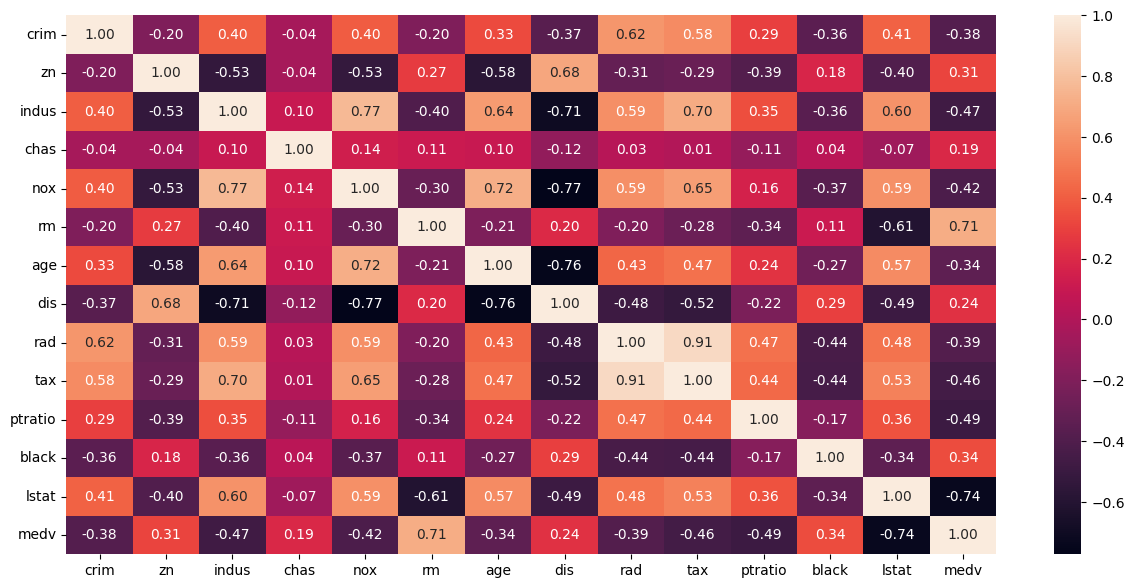

In [26]:
medv_train = pd.concat([feature_medv_train, target_medv_train], axis=1)
corr = medv_train.corr()

plt.figure(figsize=(15,7))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.show()

Melakukan drop kolom rad dan dis karena memiliki vif score yang tinggi dan dilihat dari korelasi kolom rad dan dis antar fitur. Kolom tax dan nox dipertahankan karena memiliki korelasi yang tinggi terhadap medv dibandingkan kolom rad.

In [27]:
# split train test
from sklearn.model_selection import train_test_split

feature = df_vif4.drop(columns='medv')
target = df_vif4[['medv']]

# First splitting: pretrain and test
feature_medv_pretrain, feature_medv_test, target_medv_pretrain, target_medv_test = train_test_split(feature, target, test_size=0.20, random_state=42)

# Second splitting: train and validation
feature_medv_train, feature_medv_validation, target_medv_train, target_medv_validation = train_test_split(feature_medv_pretrain, target_medv_pretrain, test_size=0.20, random_state=42)

In [28]:
feature_medv_test = feature_medv_test.drop(columns=['rad', 'dis'])
feature_medv_train = feature_medv_train.drop(columns=['rad', 'dis'])
feature_medv_validation = feature_medv_validation.drop(columns=['rad', 'dis'])

In [29]:
from sklearn.linear_model import Ridge

X_medv_train = feature_medv_train.to_numpy()
y_medv_train = target_medv_train.to_numpy()
y_medv_train = y_medv_train.reshape(len(y_medv_train),)


ridge_reg_1 = Ridge(alpha=0.0001, random_state=42)
ridge_reg_2 = Ridge(alpha=0.001, random_state=42)
ridge_reg_3 = Ridge(alpha=0.01, random_state=42)
ridge_reg_4 = Ridge(alpha=0.1, random_state=42)
ridge_reg_5 = Ridge(alpha=1, random_state=42)
ridge_reg_6 = Ridge(alpha=10, random_state=42)
ridge_reg_7 = Ridge(alpha=100, random_state=42)
ridge_reg_8 = Ridge(alpha=1000, random_state=42)

# fit the model (training)
ridge_reg_1.fit(X_medv_train, y_medv_train)
ridge_reg_2.fit(X_medv_train, y_medv_train)
ridge_reg_3.fit(X_medv_train, y_medv_train)
ridge_reg_4.fit(X_medv_train, y_medv_train)
ridge_reg_5.fit(X_medv_train, y_medv_train)
ridge_reg_6.fit(X_medv_train, y_medv_train)
ridge_reg_7.fit(X_medv_train, y_medv_train)
ridge_reg_8.fit(X_medv_train, y_medv_train)

Ridge(alpha=1000, random_state=42)

In [30]:
from sklearn.metrics import mean_squared_error

X_medv_validation = feature_medv_validation.to_numpy()
y_medv_validation = target_medv_validation.to_numpy()
y_medv_validation = y_medv_validation.reshape(len(y_medv_validation),)

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
models = [ridge_reg_1,
          ridge_reg_2,
          ridge_reg_3,
          ridge_reg_4,
          ridge_reg_5,
          ridge_reg_6,
          ridge_reg_7,
          ridge_reg_8]

for model, alpha in zip(models, alphas):
    y_predict_validation = model.predict(X_medv_validation)
    rmse = np.sqrt(mean_squared_error(y_medv_validation,y_predict_validation))
    print(f'RMSE of Ridge regression model with alpha = {alpha} is {rmse}')

RMSE of Ridge regression model with alpha = 0.0001 is 5.117953250872383
RMSE of Ridge regression model with alpha = 0.001 is 5.117903637956006
RMSE of Ridge regression model with alpha = 0.01 is 5.117414107047427
RMSE of Ridge regression model with alpha = 0.1 is 5.113102683609122
RMSE of Ridge regression model with alpha = 1 is 5.094430727191266
RMSE of Ridge regression model with alpha = 10 is 5.0501172319197485
RMSE of Ridge regression model with alpha = 100 is 4.990339560995346
RMSE of Ridge regression model with alpha = 1000 is 5.112963394223501


Berdasarkan hasil RMSE diketahui bahwa best model untuk machine learning ridge adalah menggunakan alpha 100 dengan hasil RMSE terendah yaitu 4.990

In [31]:
ridge_best = ridge_reg_7

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_medv_train.columns.tolist(),
    'coefficient':[ridge_best.intercept_] + list(ridge_best.coef_)
})

coef_df

,feature,coefficient
0,intercept,24.218030
1,crim,-0.052019
2,zn,-0.000701
3,indus,-0.004032
4,chas,0.581132
5,nox,-0.086028
6,rm,2.736915
7,age,0.042983
8,tax,0.000542
9,ptratio,-0.914612


In [32]:
from sklearn.linear_model import Lasso

# train the model
X_medv_validation = feature_medv_validation.to_numpy()
y_medv_train = target_medv_train.to_numpy()
y_medv_train = y_medv_train.reshape(len(y_medv_train),)

# define the model
# 4 models with 4 different alphas (lambda)
Lasso_reg_1 = Lasso(alpha=0.00001, random_state=42)
Lasso_reg_2 = Lasso(alpha=0.0001, random_state=42)
Lasso_reg_3 = Lasso(alpha=0.001, random_state=42)
Lasso_reg_4 = Lasso(alpha=0.01, random_state=42)
Lasso_reg_5 = Lasso(alpha=0.1, random_state=42)
Lasso_reg_6 = Lasso(alpha=1, random_state=42)
Lasso_reg_7 = Lasso(alpha=10, random_state=42)

# fit the model (training)
Lasso_reg_1.fit(X_medv_train, y_medv_train)
Lasso_reg_2.fit(X_medv_train, y_medv_train)
Lasso_reg_3.fit(X_medv_train, y_medv_train)
Lasso_reg_4.fit(X_medv_train, y_medv_train)
Lasso_reg_5.fit(X_medv_train, y_medv_train)
Lasso_reg_6.fit(X_medv_train, y_medv_train)
Lasso_reg_7.fit(X_medv_train, y_medv_train)

Lasso(alpha=10, random_state=42)

In [33]:
from sklearn.metrics import mean_squared_error

y_medv_validation = target_medv_validation.to_numpy()
y_medv_validation = y_medv_validation.reshape(len(y_medv_validation),)

alphas = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10]
models = [Lasso_reg_1,
          Lasso_reg_2,
          Lasso_reg_3,
          Lasso_reg_4,
          Lasso_reg_5,
          Lasso_reg_6,
          Lasso_reg_7]

for model, alpha in zip(models, alphas):
    y_predict_validation = model.predict(X_medv_validation)
    rmse = np.sqrt(mean_squared_error(y_medv_validation,y_predict_validation))
    print(f'RMSE of Lasso regression model with alpha = {alpha} is {rmse}')

RMSE of Lasso regression model with alpha = 1e-05 is 5.117938378042887
RMSE of Lasso regression model with alpha = 0.0001 is 5.117755142228325
RMSE of Lasso regression model with alpha = 0.001 is 5.115955950952495
RMSE of Lasso regression model with alpha = 0.01 is 5.101296278183111
RMSE of Lasso regression model with alpha = 0.1 is 5.080169848064392
RMSE of Lasso regression model with alpha = 1 is 4.988309999786156
RMSE of Lasso regression model with alpha = 10 is 5.426622694252768


Berdasarkan hasil RMSE diketahui bahwa best model untuk machine learning lasso adalah menggunakan alpha 1 dengan hasil RMSE terendah yaitu 4.988

In [34]:
lasso_best = Lasso_reg_6

coef_df = pd.DataFrame({
    'feature':['intercept'] + feature_medv_train.columns.tolist(),
    'coefficient':[lasso_best.intercept_] + list(lasso_best.coef_)
})

coef_df

,feature,coefficient
0,intercept,22.945673
1,crim,-0.034953
2,zn,0.001941
3,indus,-0.000000
4,chas,0.000000
5,nox,-0.000000
6,rm,2.572882
7,age,0.041419
8,tax,-0.001003
9,ptratio,-0.757735


Best model machine learning yang akan digunakan adalah lasso dengan alpha 1 karena memiliki nilai RMSE paling kecil

In [35]:
# prepare prediction result on train data
y_predict_train = lasso_best.predict(X_medv_train)

In [36]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

print('RMSE for training data is {}'.format(np.sqrt(mean_squared_error(y_medv_train, y_predict_train))))
print('MAE for training data is {}'.format(mean_absolute_error(y_medv_train, y_predict_train)))
print('MAPE for training data is {}'.format(mean_absolute_percentage_error(y_medv_train, y_predict_train)))

RMSE for training data is 5.2992577841643245
MAE for training data is 3.8155684789738924
MAPE for training data is 0.1801592831179


Berdasarkan hasil model didapatkan bahwa nilai MAPE data training adalah 0.1801 atau 18.01% ini berarti model memiliki rata-rata kesalahan error sebesar 18.01% dari nilai aktual. Dalam model masih perlu adanya imporve atau perbaikan karena nilai MAPE masih diatas 10%.

In [37]:
# prepare prediction result on test data
X_medv_test = feature_medv_test.to_numpy()
y_predict_test = lasso_best.predict(X_medv_test)

# ground truth target
y_medv_test = target_medv_test.to_numpy()
y_medv_test = y_medv_test.reshape(len(y_medv_test),)

In [38]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

print('RMSE for testing data is {}'.format(np.sqrt(mean_squared_error(y_medv_test, y_predict_test))))
print('MAE for testing data is {}'.format(mean_absolute_error(y_medv_test, y_predict_test)))
print('MAPE for testing data is {}'.format(mean_absolute_percentage_error(y_medv_test, y_predict_test)))

RMSE for testing data is 5.315646725734099
MAE for testing data is 3.535684907677296
MAPE for testing data is 0.18439385451147544


Berdasarkan hasil model didapatkan bahwa nilai MAPE data testing model Lasso (alpha = 1) adalah 0.1844 atau 18.44%. Ini berarti model memiliki rata-rata kesalahan sebesar 18.44% dari nilai aktual. Model masih perlu perbaikan karena nilai MAPE masih di atas 10%.

Perbedaan nilai MAPE data train (18.02%) dan data testing (18.44%) kecil, sehingga model tidak overfitting. Namun, hasil ini masih lebih buruk dibanding model Ridge pada eksperimen pertama (MAPE testing 17.14%), sehingga mendrop kolom dis tidak meningkatkan performa model.

# Kesimpulan Akhir

Berdasarkan hasil evaluasi terhadap beberapa model yang diuji, model Ridge Regression dengan alpha = 100 dan hanya mendrop kolom rad saja terpilih sebagai model terbaik dibandingkan alternatif lain yang diuji. Pemilihan alpha = 100 ini merupakan hasil dari proses hyperparameter tuning, di mana nilai tersebut memberikan performa terbaik dari sisi metrik error (RMSE, MAE, MAPE) dibandingkan nilai alpha lainnya. Regularisasi Ridge dengan alpha = 100 mampu memberikan keseimbangan yang baik antara bias dan variance, sehingga model tidak mengalami overfitting maupun underfitting secara signifikan.

Namun, meskipun menjadi model terbaik di antara yang diuji, model ini masih menghasilkan MAPE di atas 10%, yang menunjukkan bahwa tingkat kesalahan prediksi secara persentase masih tergolong belum optimal. Hal ini mengindikasikan bahwa performa model saat ini belum cukup akurat untuk beberapa kebutuhan prediksi yang memerlukan presisi tinggi.

Oleh karena itu, diperlukan improvement lebih lanjut dengan mempertimbangkan penggunaan model lain yang berpotensi menangkap pola data dengan lebih baik, seperti:

Model non-linear (misalnya Random Forest, Gradient Boosting, atau

- XGBoost) yang mampu menangkap hubungan kompleks antar fitur yang tidak dapat ditangkap oleh model linear seperti Ridge.
- Feature engineering tambahan untuk memperkaya informasi yang digunakan model.
- Ensemble methods yang menggabungkan beberapa model untuk meningkatkan akurasi prediksi.

Dengan demikian, Ridge Regression (alpha = 100) dapat dijadikan sebagai baseline model yang solid, namun eksplorasi model lain tetap diperlukan untuk menurunkan MAPE ke level yang lebih baik (idealnya di bawah 10%).

# Reflection Questions

1. Mengapa penting memahami konsep regularisasi seperti Ridge dan
Lasso dalam membangun model regresi? Bagaimana teknik ini membantu meningkatkan performa model dalam kasus prediksi dunia nyata seperti harga rumah?
- Regularisasi penting karena model regresi biasa rentan overfitting, terutama saat fitur banyak, saling berkorelasi (multikolinearitas), atau data training terbatas. Caranya dengan menambahkan penalti pada koefisien:
>- Ridge (L2) — mengecilkan semua koefisien mendekati nol, cocok untuk mengatasi multikolinearitas.
>- Lasso (L1) — bisa membuat koefisien tepat nol, sehingga sekaligus jadi seleksi fitur otomatis.

- Dalam prediksi harga rumah, fitur seperti luas tanah dan luas bangunan sering saling berkorelasi. Regularisasi membuat model lebih stabil dan tidak terlalu bergantung pada satu fitur, sehingga prediksi pada data baru lebih akurat dan tidak overfitting.

2. Bagaimana proses analisis korelasi, seleksi fitur, dan pemilihan model berdasarkan validation set membantu kamu membangun model yang lebih akurat dan dapat dipercaya? Apa hal yang paling kamu pelajari dari tahapan tersebut?
- Analisis korelasi membantu mendeteksi multikolinearitas dan melihat fitur mana yang paling berhubungan dengan target.
Seleksi fitur mengurangi noise dan kompleksitas model, sehingga risiko overfitting berkurang.
Validation set memastikan performa model diuji pada data yang belum pernah dilihat, bukan hanya training set.

- Pelajaran utama: performa bagus di training set tidak menjamin performa bagus di data baru — validasi mengajarkan pentingnya membangun model yang general dan dapat dipercaya, bukan sekadar mengejar error terkecil di data yang sudah dikenal.
